# 05 · Un modèle du prix de chaque station

Le notebook 04 mesurait l'effet de l'enseigne et de la concurrence avec une régression linéaire, variable par variable. On change ici d'approche : un modèle de **gradient boosting** (LightGBM) apprend le prix de chaque station à partir de tout ce que l'on sait d'elle, sans imposer la forme des relations ni leurs interactions. On l'ouvre ensuite avec les **valeurs de Shapley** (SHAP), qui répartissent chaque prédiction entre les caractéristiques de la station.

**Questions**
1. Peut-on prédire le prix d'une station à partir de son enseigne, de sa position, de ses services et de ses concurrents ? Avec quelle précision ?
2. Qu'est-ce qui compte le plus dans ce prix ?
3. Pourquoi telle station est-elle chère ?
4. Peut-on prévoir le prix national de la semaine prochaine ?

Comme au notebook 04, la cible est l'**écart moyen de chaque station au prix médian national du gazole** en 2025, en centimes par litre, sur les stations de métropole continentale qui publient au moins six mois. Les chiffres cités dans le texte sont recalculés et vérifiés par la dernière cellule.

In [1]:
from datetime import date
import json
from pathlib import Path

from IPython.display import Markdown, display
import lightgbm as lgb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import shap
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold, KFold, LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

from carburants import analyse, enseignes, modele, transmission

DONNEES = Path("../data")
FIGURES = Path("../rapports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
chiffres = {}

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(140)

BLEU, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#8a5cd6"
TEXTE, TEXTE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "axes.edgecolor": GRILLE, "axes.labelcolor": TEXTE_2, "axes.titlecolor": TEXTE,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "xtick.color": TEXTE_2, "ytick.color": TEXTE_2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})
MOIS = ["janv.", "févr.", "mars", "avr.", "mai", "juin", "juil.", "août", "sept.", "oct.", "nov.", "déc."]

def sauver(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png")

def virgule(valeur, _=None, decimales=None):
    texte = f"{valeur:g}" if decimales is None else f"{valeur:.{decimales}f}"
    return texte.replace(".", ",").replace("-", "−")

def signe(valeur, decimales=1):
    return f"{valeur:+.{decimales}f}".replace(".", ",").replace("-", "−")

/home/claude/prix-carburants-bornes/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Les données

On reprend la reconstruction du notebook 04 (prix hebdomadaires, enseignes d'OpenStreetMap, concurrents calculés parmi les stations qui publient dans l'année) et on y ajoute ce que les stations déclarent dans le flux officiel : leurs **services** (boutique, lavage, toilettes, distributeur de billets…), l'**automate 24 h/24**, et les **carburants** qu'elles vendent. Au total, chaque station est décrite par une trentaine de caractéristiques, rangées en sept familles :

| Famille | Caractéristiques |
|---|---|
| Enseigne | l'enseigne d'OpenStreetMap, les stations Total Access à part des autres TotalEnergies (les enseignes de moins de 40 stations sont regroupées, les stations sans enseigne connue forment leur propre groupe) |
| Autoroute | station d'autoroute ou non |
| Position géographique | latitude et longitude |
| Carburants vendus | SP95, SP98, E10, E85, GPL |
| Services | automate 24 h/24, nombre de services, douze services courants |
| Concurrence | nombre de stations à moins de 1, 3, 5 et 10 km, distance de la plus proche, de la grande surface la plus proche et de la station TotalEnergies (hors Access) la plus proche |
| Ancienneté | années depuis la première publication de prix (les données commencent en 2007) |

Le département n'est pas donné au modèle : la latitude et la longitude jouent ce rôle. La construction de la table est dans `carburants.modele.table_stations`, que réutilisera l'application.

In [2]:
HISTORIQUE = DONNEES / "historique"
ANNEE = 2025
prix = analyse.charger_historique(HISTORIQUE)
hebdo = analyse.prix_hebdo(prix.filter(pl.col("carburant") == "Gazole"))
hebdo = hebdo.with_columns(ecart=(pl.col("prix") - pl.col("prix").median().over("semaine")) * 100)

fichier_enseignes = sorted((DONNEES / "enseignes").glob("stations_enseignes_*.parquet"))[-1]
appariement = pl.read_parquet(fichier_enseignes).with_columns(
    enseigne=pl.when(pl.col("enseigne").is_not_null()).then(
        pl.struct("osm_marque", "osm_nom").map_elements(
            lambda r: enseignes.normaliser(r["osm_marque"], r["osm_nom"]), return_dtype=pl.Utf8
        )
    )
).with_columns(
    grande_surface=pl.col("enseigne").is_in(list(enseignes.GRANDES_SURFACES)).fill_null(False),
    # Les stations Total Access, à bas prix, forment une enseigne à part
    enseigne_detaillee=pl.when((pl.col("enseigne") == "TotalEnergies") & enseignes.total_access(pl.col("osm_marque"), pl.col("osm_nom")))
    .then(pl.lit("TotalEnergies Access")).otherwise(pl.col("enseigne")),
)
stations = (
    analyse.stations_connues(HISTORIQUE).rename({"id": "station_id"})
    .filter(pl.col("latitude").is_between(42.3, 51.5), pl.col("longitude").is_between(-5.5, 8.3), pl.col("departement") != "20")
    .join(appariement.select("station_id", pl.col("enseigne_detaillee").alias("enseigne"), "grande_surface"), on="station_id", how="left")
    .with_columns(pl.col("grande_surface").fill_null(False))
)

def table_annee(annee):
    """Une ligne par station active dans l'année : écart moyen au prix médian et caractéristiques."""
    description = pl.read_parquet(HISTORIQUE / f"stations_{annee}.parquet", columns=["id", "automate_24_24", "services"])
    vendus = modele.carburants_vendus(analyse.charger_historique(HISTORIQUE, [annee]))
    table = modele.table_stations(hebdo, stations, description.rename({"id": "station_id"}), vendus, annee)
    return table.with_columns(region=modele.region(pl.col("departement")))

table = table_annee(ANNEE)
X = modele.matrice(table)
y = table["ecart"].to_numpy()
departements = table["departement"].to_numpy()
regions = table["region"].to_numpy()
assert table["region"].null_count() == 0
chiffres["stations"] = table.height
chiffres["caracteristiques"] = X.shape[1]
chiffres["ecart_type"] = float(y.std())
chiffres["part_anciennete_tronquee"] = float((table["debut"] <= date(2007, 1, 7)).mean() * 100)
print(f"{table.height:,} stations, {X.shape[1]} caractéristiques ; écart-type de la cible : {y.std():.1f} centimes")
table.group_by("enseigne").agg(stations=pl.len(), ecart_moyen=pl.col("ecart").mean().round(1)).sort("ecart_moyen")

9,273 stations, 31 caractéristiques ; écart-type de la cible : 7.2 centimes


enseigne,stations,ecart_moyen
str,u32,f64
"""E.Leclerc""",621,-3.0
"""Système U""",693,-2.6
"""Netto""",71,-2.0
"""Intermarché""",1292,-1.9
"""Auchan""",179,-1.6
"""Carrefour""",1045,-0.2
"""TotalEnergies Access""",466,0.6
"""Autre""",151,2.1
"""Inconnue""",2132,2.4


## 1. Le modèle prédit-il bien ?

On mesure la précision **hors échantillon** : chaque station est prédite par un modèle entraîné sans elle. Trois découpages, du plus facile au plus exigeant :
- **au hasard**, en cinq groupes : le modèle a vu des stations voisines de celle qu'il prédit ;
- **par département**, en cinq groupes : tous les départements d'un groupe sont mis de côté ensemble ;
- **par région** : chacune des douze régions est prédite par un modèle entraîné sur les onze autres.

On compare le gradient boosting à trois références plus simples :
- **la moyenne** : toutes les stations au même écart ;
- **l'enseigne** : la moyenne de l'enseigne, séparément pour les stations d'autoroute ;
- **une régression linéaire** (ridge) avec les mêmes caractéristiques, plus le département (ignoré pour un département jamais vu).

Les réglages du gradient boosting sont fixés a priori (`modele.PARAMETRES`), sans recherche sur ces validations.

In [3]:
PLIS = {
    "au hasard": (KFold(5, shuffle=True, random_state=0), None),
    "par département": (GroupKFold(5), departements),
    "par région": (LeaveOneGroupOut(), regions),
}
SUFFIXES = {"au hasard": "hasard", "par département": "dep", "par région": "reg"}

def predictions_reference(X, y, plis, groupes, nom):
    """Prédictions hors échantillon des modèles de référence."""
    prediction = np.full(len(y), np.nan)
    for apprentissage, test in plis.split(X, y, groupes):
        if nom == "moyenne":
            prediction[test] = y[apprentissage].mean()
        elif nom == "enseigne":
            cle = X["enseigne"].astype(str) + X["autoroute"].astype(str)
            moyennes = pd.Series(y[apprentissage]).groupby(cle.iloc[apprentissage].to_numpy()).mean()
            prediction[test] = cle.iloc[test].map(moyennes).fillna(y[apprentissage].mean()).to_numpy()
        else:
            categories = ["enseigne", "departement"]
            donnees = X.assign(departement=departements)
            lineaire = make_pipeline(
                ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore"), categories)], remainder="passthrough"),
                RidgeCV(alphas=np.logspace(-2, 3, 11)),
            )
            numeriques = donnees.drop(columns=categories).columns
            donnees[numeriques] = donnees[numeriques].astype(float)
            # Les comptes de concurrents en logarithme, comme au notebook 04
            for colonne in [c for c in numeriques if c.startswith("voisins_")]:
                donnees[colonne] = np.log1p(donnees[colonne])
            lineaire.fit(donnees.iloc[apprentissage], y[apprentissage])
            prediction[test] = lineaire.predict(donnees.iloc[test])
    return prediction

MODELES = ["moyenne", "enseigne", "régression linéaire", "gradient boosting"]
predictions, lignes = {}, []
for decoupage, (plis, groupes) in PLIS.items():
    for nom in MODELES:
        if nom == "gradient boosting":
            prediction = modele.predictions_croisees(X, y, plis, groupes)
        else:
            prediction = predictions_reference(X, y, plis, groupes, nom)
        predictions[decoupage, nom] = prediction
        score = modele.scores(y, prediction)
        lignes.append({"découpage": decoupage, "modèle": nom, "erreur moyenne (c)": round(score["mae"], 2), "R²": round(score["r2"], 3)})
        cle = {"moyenne": "moyenne", "enseigne": "enseigne", "régression linéaire": "lineaire", "gradient boosting": "gbm"}[nom]
        chiffres[f"mae_{cle}_{SUFFIXES[decoupage]}"] = score["mae"]
        chiffres[f"r2_{cle}_{SUFFIXES[decoupage]}"] = score["r2"]
residus = y - predictions["au hasard", "gradient boosting"]
chiffres["part_moins_2c"] = float((np.abs(residus) < 2).mean() * 100)
chiffres["gain_lineaire"] = (1 - chiffres["mae_gbm_hasard"] / chiffres["mae_lineaire_hasard"]) * 100
pl.DataFrame(lignes)

découpage,modèle,erreur moyenne (c),R²
str,str,f64,f64
"""au hasard""","""moyenne""",5.51,-0.001
"""au hasard""","""enseigne""",3.24,0.573
"""au hasard""","""régression linéaire""",2.84,0.665
"""au hasard""","""gradient boosting""",2.39,0.752
"""par département""","""moyenne""",5.53,-0.005
"""par département""","""enseigne""",3.28,0.563
"""par département""","""régression linéaire""",3.22,0.595
"""par département""","""gradient boosting""",2.56,0.723
"""par région""","""moyenne""",5.56,-0.015


In [4]:
# Région par région : l'erreur moyenne (réel − prédit) quand la région entière est mise de côté
biais = pd.Series(y - predictions["par région", "gradient boosting"]).groupby(regions).mean().sort_values()
for nom, valeur in biais.items():
    chiffres[f"biais_region_{nom}"] = float(valeur)
assert biais.idxmax() == "Île-de-France"
biais.round(2).to_frame("réel − prédit (c)")

,réel − prédit (c)
Hauts-de-France,-2.28
Grand Est,-1.56
Bretagne,-1.39
Occitanie,-0.77
Centre-Val de Loire,-0.71
Pays de la Loire,-0.43
Nouvelle-Aquitaine,-0.39
Bourgogne-Franche-Comté,-0.32
Provence-Alpes-Côte d'Azur,-0.13
Normandie,0.17


Prédire le même écart pour toutes les stations se trompe en moyenne de 5,5 centimes. Connaître l'enseigne (et l'autoroute) ramène l'erreur à 3,2 centimes et explique déjà 57,28 % des différences entre stations. La régression linéaire, qui ajoute toutes les autres caractéristiques et le département, descend à 2,8 centimes (R² de 0,66).

Le **gradient boosting** fait mieux : **2,4 centimes** d'erreur moyenne et un R² de **0,75**, soit 16 % d'erreur en moins que la régression linéaire. 59 % des stations sont prédites à moins de 2 centimes près.

Sur des départements jamais vus, la précision baisse peu (2,6 centimes, R² de 0,72) : un département ressemble à ses voisins, que le modèle a vus. Mettre de côté une **région entière** coûte davantage (3,0 centimes, R² de 0,64). Ce qui tient à l'enseigne et au type de station se transpose d'une région à l'autre ; le niveau propre à une région, non : l'**Île-de-France**, prédite à partir des onze autres, est sous-estimée de 4,9 centimes en moyenne.

Le reste de l'écart tient à ce que les données ne disent pas : le volume vendu, le loyer, la politique commerciale du gérant, la clientèle de passage.

## 2. Qu'est-ce qui fait le prix ?

On entraîne le modèle sur toutes les stations, puis on calcule les **valeurs de Shapley** de chaque prédiction : pour chaque station, la contribution de chaque caractéristique à l'écart entre sa prédiction et la moyenne. Les contributions s'additionnent exactement. Comme plusieurs caractéristiques mesurent la même chose (le nombre de concurrents à 3 et à 5 km, par exemple), on additionne les contributions par famille avant de mesurer leur poids : l'**importance** d'une famille est la valeur absolue moyenne de sa contribution, en centimes.

Une seconde mesure complète la première : la **perte de précision** quand on retire toute une famille du modèle (validation au hasard). Elle dit ce qu'aucune autre famille ne peut remplacer.

In [5]:
gbm = lgb.LGBMRegressor(**modele.PARAMETRES).fit(X, y)
explicateur = shap.TreeExplainer(gbm)
valeurs = explicateur.shap_values(X)
base = float(np.ravel(explicateur.expected_value)[0])
familles = modele.contributions_par_famille(valeurs, list(X.columns))
importance = familles.abs().mean().sort_values(ascending=False)
for famille, poids in importance.items():
    chiffres[f"importance_{famille}"] = poids
chiffres["base"] = base
chiffres["ratio_enseigne"] = importance.iloc[0] / importance.iloc[1]
chiffres["part_enseigne"] = importance.iloc[0] / importance.sum() * 100
assert importance.index[0] == "Enseigne" and importance.index[1] == "Autoroute"
# Vérification de l'additivité : base + contributions = prédiction
assert np.allclose(base + valeurs.sum(axis=1), gbm.predict(X), atol=1e-6)

# Perte de précision quand on retire une famille
perte = {}
for famille, colonnes_famille in modele.FAMILLES.items():
    sans = modele.predictions_croisees(X.drop(columns=colonnes_famille), y, KFold(5, shuffle=True, random_state=0))
    perte[famille] = modele.scores(y, sans)["mae"] - chiffres["mae_gbm_hasard"]
    chiffres[f"perte_{famille}"] = perte[famille]
pd.DataFrame({"importance (c)": importance.round(2), "erreur en plus sans la famille (c)": pd.Series(perte).round(3)})

,importance (c),erreur en plus sans la famille (c)
Ancienneté,0.24,0.030
Autoroute,1.13,0.182
Carburants vendus,0.66,0.074
Concurrence,0.61,0.008
Enseigne,2.74,0.579
Position géographique,0.87,0.263
Services,1.00,0.188


In [6]:
colonnes = list(X.columns)
def contribution(colonne):
    return valeurs[:, colonnes.index(colonne)]

# Effet moyen de l'enseigne (valeurs de Shapley)
noms_enseignes = X["enseigne"].astype(str).to_numpy()
par_enseigne = (
    pl.DataFrame({"enseigne": noms_enseignes.tolist(), "shap": contribution("enseigne")})
    .group_by("enseigne").agg(effet=pl.col("shap").mean(), stations=pl.len()).sort("effet")
)
for nom in ["E.Leclerc", "Carrefour", "TotalEnergies", "TotalEnergies Access", "Shell", "Eni", "Inconnue"]:
    chiffres[f"enseigne_{nom}"] = par_enseigne.filter(enseigne=nom)["effet"].item()
chiffres["enseigne_ecart_extremes"] = par_enseigne["effet"].max() - par_enseigne["effet"].min()
gms_effets = par_enseigne.filter(pl.col("enseigne").is_in(list(enseignes.GRANDES_SURFACES)))
assert gms_effets.sort("effet")["enseigne"][-1] == "Carrefour"  # la plus chère des grandes surfaces
chiffres["autoroute"] = float(contribution("autoroute")[X["autoroute"] == 1].mean())

# Dépendance partielle : la même enseigne donnée à toutes les stations, le reste inchangé
dependance = {e: modele.dependance_partielle(gbm, X, "enseigne", e) for e in X["enseigne"].cat.categories}
for nom in ["Eni", "TotalEnergies", "TotalEnergies Access"]:
    chiffres[f"dp_{nom}_leclerc"] = dependance[nom] - dependance["E.Leclerc"]
# Écart à la moyenne des grandes surfaces (pondérée par leur nombre de stations), comparable au notebook 04
dans_gms = np.isin(noms_enseignes, list(enseignes.GRANDES_SURFACES))
poids_gms = pd.Series(noms_enseignes[dans_gms]).value_counts()
dp_gms = sum(dependance[e] * n for e, n in poids_gms.items()) / poids_gms.sum()
shap_gms = float(contribution("enseigne")[dans_gms].mean())
chiffres04 = json.loads(Path("../rapports/chiffres_04.json").read_text())
for nom, cle in [("TotalEnergies", "total"), ("TotalEnergies Access", "access")]:
    chiffres[f"dp_{cle}_gms"] = dependance[nom] - dp_gms
    chiffres[f"shap_{cle}_gms"] = chiffres[f"enseigne_{nom}"] - shap_gms
    chiffres[f"nb04_{cle}_gms"] = chiffres04[f"reg_{cle}_2025"]

# Quelques caractéristiques une à une : contribution moyenne avec et sans
def avec_sans(colonne):
    presente = X[colonne].to_numpy() == 1
    return float(contribution(colonne)[presente].mean()), float(contribution(colonne)[~presente].mean()), float(presente.mean() * 100)

for colonne in ["vend_e10", "dab", "atelier"]:
    chiffres[f"{colonne}_avec"], chiffres[f"{colonne}_sans"], chiffres[f"{colonne}_part"] = avec_sans(colonne)
chiffres["sans_e10_part"] = 100 - chiffres["vend_e10_part"]
# Ce que ces caractéristiques disent du type de station
gms = table["grande_surface"].to_numpy()
connue = table["enseigne_osm"].is_not_null().to_numpy()
chiffres["gms_part"] = float(gms.mean() * 100)
chiffres["dab_gms_part"] = float(gms[X["dab"].to_numpy() == 1].mean() * 100)
sans_e10 = X["vend_e10"].to_numpy() == 0
chiffres["sans_e10_voisins"] = float(np.median(X["voisins_10km"][sans_e10]))
chiffres["avec_e10_voisins"] = float(np.median(X["voisins_10km"][~sans_e10]))
chiffres["sans_e10_inconnue"] = float((~connue[sans_e10]).mean() * 100)
chiffres["inconnue_part"] = float((~connue).mean() * 100)

# Concurrence : la famille repère aussi le cœur très dense de l'agglomération parisienne
concurrence_famille = familles["Concurrence"].to_numpy()
seuil_coeur = float(np.percentile(X["voisins_10km"], 99))
coeur = X["voisins_10km"].to_numpy() >= seuil_coeur
chiffres["coeur_seuil"] = seuil_coeur
chiffres["coeur_concurrence"] = float(concurrence_famille[coeur].mean())
chiffres["coeur_part_idf"] = float(np.isin(departements[coeur], ["75", "92", "93", "94"]).mean() * 100)
chiffres["hors_coeur_p10"], chiffres["hors_coeur_p90"] = np.percentile(concurrence_famille[~coeur], [10, 90])
gms_km = X["gms_km"].to_numpy()
chiffres["gms_proche"] = float(contribution("gms_km")[gms_km < 1].mean())
chiffres["gms_loin"] = float(contribution("gms_km")[gms_km > 10].mean())
par_enseigne.with_columns(pl.col("effet").round(2), dependance_partielle=pl.col("enseigne").replace_strict(dependance).round(2))

enseigne,effet,stations,dependance_partielle
str,f64,u32,f64
"""E.Leclerc""",-4.23,621,-1.89
"""Netto""",-3.18,71,-0.72
"""Système U""",-3.11,693,-0.73
"""Intermarché""",-2.95,1292,-0.68
"""Auchan""",-2.68,179,-0.23
"""TotalEnergies Access""",-1.65,466,1.05
"""Carrefour""",-1.64,1045,0.87
"""Autre""",-0.49,151,1.96
"""Inconnue""",-0.01,2132,2.39


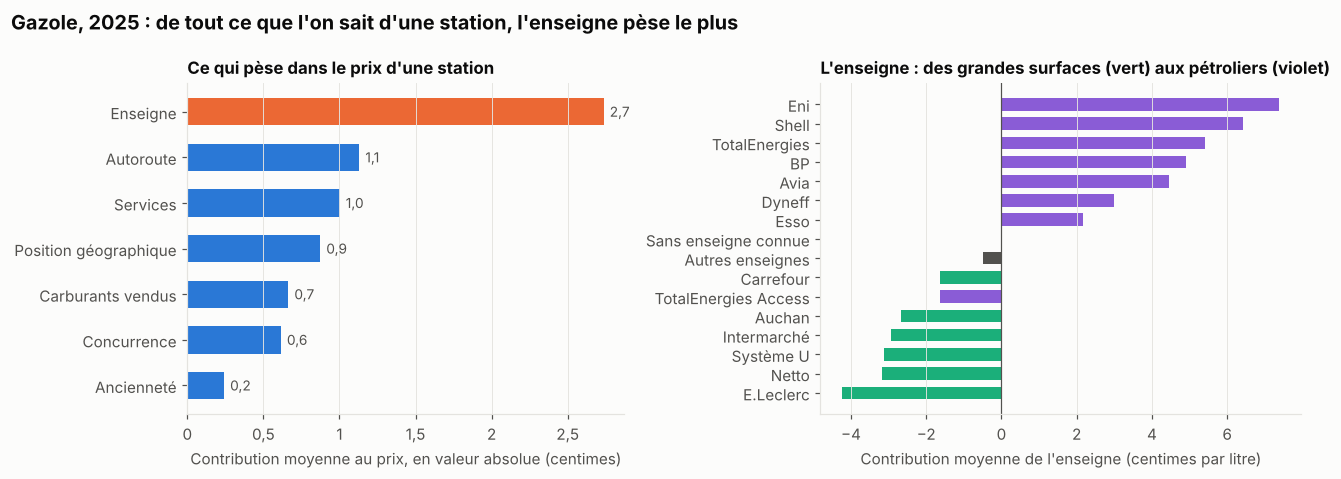

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.1]})
ax = axes[0]
ordre = importance.sort_values()
couleurs = [ORANGE if famille == "Enseigne" else BLEU for famille in ordre.index]
ax.barh(ordre.index, ordre.to_numpy(), color=couleurs, height=0.6)
for yi, valeur in enumerate(ordre.to_numpy()):
    ax.annotate(virgule(valeur, decimales=1), (valeur, yi), xytext=(4, 0), textcoords="offset points", va="center",
                fontsize=9, color=TEXTE_2)
ax.set_xlabel("Contribution moyenne au prix, en valeur absolue (centimes)")
ax.xaxis.set_major_formatter(virgule)
ax.set_title("Ce qui pèse dans le prix d'une station", fontsize=11)
ax.grid(axis="y", visible=False)

ax = axes[1]
y_pos = np.arange(par_enseigne.height)
couleurs = [AQUA if e in enseignes.GRANDES_SURFACES else (TEXTE_2 if e in ("Inconnue", "Autre") else VIOLET)
            for e in par_enseigne["enseigne"]]
ax.barh(y_pos, par_enseigne["effet"], color=couleurs, height=0.65)
ax.set_yticks(y_pos, [{"Inconnue": "Sans enseigne connue", "Autre": "Autres enseignes"}.get(e, e) for e in par_enseigne["enseigne"]])
ax.axvline(0, color=TEXTE_2, linewidth=0.8)
ax.set_xlabel("Contribution moyenne de l'enseigne (centimes par litre)")
ax.xaxis.set_major_formatter(virgule)
ax.set_title("L'enseigne : des grandes surfaces (vert) aux pétroliers (violet)", fontsize=11)
ax.grid(axis="y", visible=False)
fig.suptitle("Gazole, 2025 : de tout ce que l'on sait d'une station, l'enseigne pèse le plus",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TEXTE)
fig.tight_layout()
sauver(fig, "17_modele_importance")

**L'enseigne pèse le plus**, avec une contribution moyenne de 2,7 centimes, 2,4 fois celle de la famille suivante, l'autoroute, et 38 % du total des familles. C'est aussi celle qui manque le plus quand on la retire : l'erreur augmente de 0,58 centime.

Le modèle retrouve la hiérarchie du notebook 04 : E.Leclerc tire le prix de 4,2 centimes sous la moyenne, TotalEnergies le pousse de 5,4 centimes au-dessus, Eni de 7,4 et Shell de 6,4. Pour isoler l'enseigne, on peut aussi la changer sans toucher au reste : donner à toutes les stations l'enseigne Eni plutôt qu'E.Leclerc fait monter le prix prédit de 11,8 centimes en moyenne, TotalEnergies plutôt qu'E.Leclerc de 9,7. Les stations **Total Access**, format à bas prix du groupe, se placent au niveau de **Carrefour**, la plus chère des grandes surfaces (−1,6 contre −1,6 centimes), loin des autres TotalEnergies : sous un même logo, deux politiques de prix.

Ces écarts recoupent la régression du notebook 04. Face à la moyenne des grandes surfaces, TotalEnergies coûte 8,3 centimes de plus selon le modèle (dépendance partielle), contre 9,8 au notebook 04 ; Total Access 1,5 contre 1,9. Le gradient boosting trouve un peu moins, sans doute parce qu'une partie de l'effet de l'enseigne passe par les services et les carburants, qui vont avec elle.

**L'autoroute** vient ensuite : peu de stations, mais un effet massif (+12 centimes pour une station d'autoroute).

Les **services** et les **carburants vendus** décrivent le type de station plus qu'ils ne fixent son prix. Le modèle s'en sert comme d'indices :
- une station qui ne vend pas d'E10 (19 % des stations) reçoit +1,3 centime, contre −0,4 pour les autres. Ce sont plutôt des stations de zones peu denses : 5 stations à moins de 10 km en médiane, contre 10, et un peu plus souvent sans enseigne connue (29 %, contre 23 % en tout) ;
- une station avec atelier de réparation reçoit +1,6 centimes ;
- une station avec distributeur de billets reçoit −0,6 centime : 59 % sont des grandes surfaces, contre 42 % de l'ensemble.

Ce sont des indices du type de station, pas des leviers : retirer le distributeur de billets ne rendrait pas une station plus chère.

**La concurrence, au sens strict, pèse peu**, comme au notebook 04 : une grande surface à moins de 1 km enlève en moyenne 0,06 centime, en être à plus de 10 km en ajoute 0,26. Retirer toute la famille n'augmente l'erreur que de 0,008 centime : la position et le type de station disent presque la même chose. Les comptes de stations servent surtout de **repère géographique** : ils signalent le cœur dense de l'agglomération parisienne. Pour le 1 % de stations qui comptent au moins 124 stations à moins de 10 km (100 % sont à Paris ou en petite couronne), la famille « concurrence » ajoute en moyenne +6,3 centimes. Il est peu probable que la concurrence y fasse monter les prix : la densité marque un lieu, avec son foncier cher et sa clientèle moins attentive aux prix, que les données ne mesurent pas. Ailleurs, la famille reste entre −0,8 et +0,6 centime pour 80 % des stations.

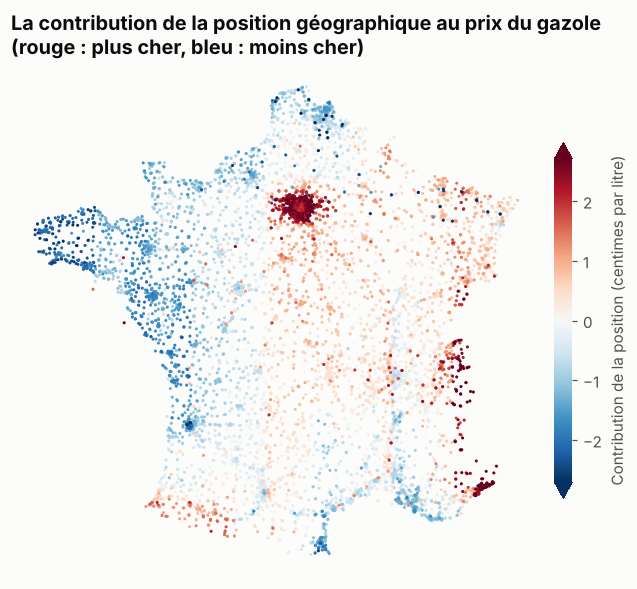

In [8]:
geo = familles["Position géographique"].to_numpy()
fig, ax = plt.subplots(figsize=(7.5, 7))
ordre = np.argsort(np.abs(geo))  # les stations les plus marquées par-dessus
limite = np.percentile(np.abs(geo), 98)
points = ax.scatter(X["longitude"].to_numpy()[ordre], X["latitude"].to_numpy()[ordre], c=geo[ordre], s=4,
                    cmap="RdBu_r", vmin=-limite, vmax=limite, linewidths=0)
ax.set_aspect(1 / np.cos(np.radians(46.5)))
ax.set_axis_off()
barre = fig.colorbar(points, ax=ax, shrink=0.6, pad=0.02, extend="both")
barre.set_label("Contribution de la position (centimes par litre)", color=TEXTE_2)
barre.ax.yaxis.set_major_formatter(virgule)
barre.outline.set_visible(False)
ax.set_title("La contribution de la position géographique au prix du gazole\n(rouge : plus cher, bleu : moins cher)")
sauver(fig, "18_modele_carte")

La carte montre la part du prix que le modèle attribue à la latitude et à la longitude. Elle ne dit pas tout du lieu : une partie de l'effet de l'Île-de-France passe par la famille « concurrence », qui repère le cœur de l'agglomération. Pour lire la géographie des prix, on additionne donc, région par région, les contributions moyennes de chaque famille, en regroupant la position et la concurrence sous le nom de **lieu**. L'écart de chaque région à la station moyenne se décompose alors exactement : enseigne, autoroute, lieu, autres caractéristiques, et une part que le modèle n'explique pas.

In [9]:
GROUPES = {
    "enseigne": ["Enseigne"],
    "autoroute": ["Autoroute"],
    "lieu": ["Position géographique", "Concurrence"],
    "autres": ["Services", "Carburants vendus", "Ancienneté"],
}
moyenne = y.mean()
lignes = []
for nom in modele.REGIONS:
    dans = regions == nom
    ligne = {"région": nom, "stations": int(dans.sum()), "écart à la moyenne": y[dans].mean() - moyenne}
    for groupe, noms_familles in GROUPES.items():
        ligne[groupe] = familles.loc[dans, noms_familles].sum(axis=1).mean()
    ligne["non expliqué"] = ligne["écart à la moyenne"] - sum(ligne[g] for g in GROUPES)
    ligne["dont position"] = familles.loc[dans, "Position géographique"].mean()
    ligne["dont concurrence"] = familles.loc[dans, "Concurrence"].mean()
    ligne["grandes surfaces (%)"] = gms[dans].mean() * 100
    for cle, valeur in ligne.items():
        if cle not in ("région", "stations"):
            chiffres[f"region_{nom}_{cle}"] = float(valeur)
    lignes.append(ligne)
par_region = pd.DataFrame(lignes).set_index("région").sort_values("écart à la moyenne")
assert par_region.index[-1] == "Île-de-France" and par_region.index[0] == "Bretagne"
assert par_region.loc["Île-de-France", "lieu"] == par_region["lieu"].max()
assert par_region.loc["Bretagne", "lieu"] == par_region["lieu"].min()
par_region.round(2)

,stations,écart à la moyenne,enseigne,autoroute,lieu,autres,non expliqué,dont position,dont concurrence,grandes surfaces (%)
région,,,,,,,,,,
Bretagne,527,-3.45,-1.03,-0.63,-1.66,-0.17,0.04,-1.54,-0.13,55.98
Pays de la Loire,529,-1.94,-0.64,0.01,-1.28,0.01,-0.05,-1.12,-0.16,54.44
Normandie,544,-1.63,-0.38,-0.19,-1.10,0.05,-0.01,-0.81,-0.28,51.10
Hauts-de-France,781,-1.47,-0.33,-0.04,-0.74,-0.27,-0.08,-0.49,-0.26,44.05
Nouvelle-Aquitaine,1085,-1.16,-0.54,0.06,-0.61,-0.01,-0.06,-0.47,-0.14,51.61
Occitanie,1058,-0.65,-0.00,-0.12,-0.37,-0.13,-0.02,-0.16,-0.22,43.57
Centre-Val de Loire,429,-0.17,-0.44,0.46,0.18,-0.08,-0.29,0.34,-0.16,47.79
Provence-Alpes-Côte d'Azur,752,0.33,0.47,-0.03,-0.10,-0.03,0.02,0.17,-0.26,33.64
Grand Est,827,0.46,0.28,0.00,0.24,-0.07,0.01,0.51,-0.27,36.52


L'**Île-de-France** est la région la plus chère : ses stations vendent le gazole 5,1 centimes au-dessus de la station moyenne. Le lieu en explique 3,6 (la position 1,9, la densité du cœur de l'agglomération 1,8), l'enseigne 1,1. La **Bretagne** est la moins chère (−3,5 centimes) : par le lieu (−1,7), par ses enseignes (−1,0 ; 56 % de grandes surfaces, contre 42 % en France) et par le peu de stations d'autoroute (−0,6).

Ailleurs, les écarts sont plus faibles et mêlent le lieu, les enseignes et les autoroutes dans des proportions qui varient d'une région à l'autre : la géographie des prix n'est qu'en partie une affaire de lieu.

## 3. Pourquoi cette station est-elle chère ?

Les valeurs de Shapley expliquent aussi une prédiction isolée. Pour que l'exemple soit honnête, on prend la station hors autoroute que le modèle prédit la plus chère **sans l'avoir vue** (prédiction hors échantillon, découpage au hasard), et on décompose sa prédiction avec le modèle qui l'a faite. La position et la concurrence sont regroupées dans le **lieu**.

In [10]:
prediction_hors, pli, modeles_plis = modele.predictions_croisees(
    X, y, KFold(5, shuffle=True, random_state=0), renvoyer_modeles=True
)
hors_autoroute = np.flatnonzero(X["autoroute"].to_numpy() == 0)
i = int(hors_autoroute[np.argmax(prediction_hors[hors_autoroute])])
explicateur_i = shap.TreeExplainer(modeles_plis[pli[i]])
valeurs_i = explicateur_i.shap_values(X.iloc[[i]])
base_i = float(np.ravel(explicateur_i.expected_value)[0])
assert np.isclose(base_i + valeurs_i.sum(), prediction_hors[i], atol=1e-6)
familles_i = modele.contributions_par_famille(valeurs_i, colonnes).iloc[0]
familles_i["Lieu"] = familles_i.pop("Position géographique") + familles_i.pop("Concurrence")
decomposition = familles_i.sort_values(key=np.abs, ascending=False)
station = table.row(i, named=True)
chiffres["exemple_prediction"] = float(prediction_hors[i])
chiffres["exemple_reel"] = float(y[i])
chiffres["exemple_base"] = base_i
for famille, valeur in decomposition.items():
    chiffres[f"exemple_{famille}"] = float(valeur)

ville = pl.read_parquet(HISTORIQUE / f"stations_{ANNEE}.parquet", columns=["id", "ville"]).filter(id=station["station_id"])["ville"].item()
non_vendus = [nom.removesuffix("c") for nom in modele.CARBURANTS_OFFERTS if not station[f"vend_{nom.lower()}"]]
ARTICLES = {"Enseigne": "l'enseigne", "Autoroute": "l'autoroute", "Lieu": "le lieu", "Carburants vendus": "les carburants vendus",
            "Services": "les services", "Ancienneté": "l'ancienneté"}
carburants_texte = (
    "vend tous les carburants courants" if not non_vendus
    else f"ne vend pas de {non_vendus[0]}" if len(non_vendus) == 1
    else "ne vend ni " + " ni ".join(non_vendus)
)
display(Markdown(
    f"**La station {station['station_id']}**, à {ville.title()} ({station['cp']}), enseigne {station['enseigne_osm'] or 'inconnue'}, "
    f"a publié ses prix {station['semaines']} semaines en {ANNEE} et publie depuis {station['anciennete']:.0f} ans. "
    f"Elle {carburants_texte}, et compte {station['voisins_5km']} stations à moins de 5 km. "
    f"Son gazole est {virgule(abs(y[i]), decimales=1)} centimes {'au-dessus' if y[i] > 0 else 'en dessous'} du prix médian national ; sans l'avoir vue, le modèle en prédit "
    f"{signe(prediction_hors[i])}. Partant de la moyenne des stations ({signe(base_i)} centimes), "
    + ", ".join(f"{ARTICLES[famille]} {signe(valeur)}"
                for famille, valeur in decomposition.items())
    + "."
))
decomposition.round(2).to_frame("contribution (c)")

**La station 77290003**, à Compans (77290), enseigne Shell, a publié ses prix 52 semaines en 2025 et publie depuis 3 ans. Elle ne vend ni SP95 ni SP98 ni E10 ni E85 ni GPL, et compte 2 stations à moins de 5 km. Son gazole est 25,3 centimes au-dessus du prix médian national ; sans l'avoir vue, le modèle en prédit +27,7. Partant de la moyenne des stations (+2,3 centimes), les carburants vendus +8,6, l'enseigne +7,1, le lieu +3,8, l'ancienneté +3,3, les services +2,8, l'autoroute −0,2.

,contribution (c)
Carburants vendus,8.58
Enseigne,7.13
Lieu,3.77
Ancienneté,3.29
Services,2.80
Autoroute,-0.19


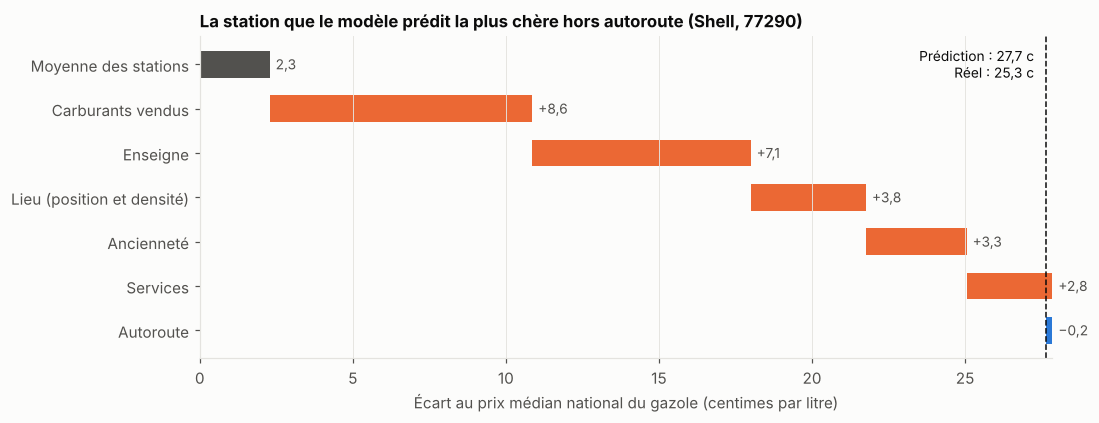

In [11]:
fig, ax = plt.subplots(figsize=(10, 3.8))
etapes = [("Moyenne des stations", base_i)] + [("Lieu (position et densité)" if nom == "Lieu" else nom, v) for nom, v in decomposition.items()]
cumul = 0.0
for k, (nom, valeur) in enumerate(etapes):
    debut = 0.0 if k == 0 else cumul
    cumul = valeur if k == 0 else cumul + valeur
    couleur = TEXTE_2 if k == 0 else (ORANGE if valeur > 0 else BLEU)
    ax.barh(len(etapes) - k, cumul - debut, left=debut, color=couleur, height=0.6)
    ax.annotate(virgule(valeur, decimales=1) if k == 0 else signe(valeur),
                (max(debut, cumul), len(etapes) - k), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=TEXTE_2)
ax.axvline(cumul, color=TEXTE, linewidth=1, linestyle="--")
ax.annotate(f"Prédiction : {virgule(cumul, decimales=1)} c\nRéel : {virgule(y[i], decimales=1)} c", (cumul, len(etapes)),
            xytext=(-8, 0), textcoords="offset points", ha="right", va="center", fontsize=9, color=TEXTE)
ax.set_yticks(range(len(etapes), 0, -1), [nom for nom, _ in etapes])
ax.set_xlabel("Écart au prix médian national du gazole (centimes par litre)")
ax.xaxis.set_major_formatter(virgule)
ax.grid(axis="y", visible=False)
ax.set_title(f"La station que le modèle prédit la plus chère hors autoroute ({station['enseigne_osm'] or 'enseigne inconnue'}, {station['cp']})",
             fontsize=11)
sauver(fig, "19_modele_station")

C'est ce type de décomposition qu'affichera l'application de l'étape 7 pour chaque station. Elle se lit avec prudence : quand deux familles se recouvrent (la position et la concurrence, les services et l'enseigne), deux modèles presque identiques peuvent répartir différemment la même prédiction entre elles. C'est pourquoi on regroupe ici le lieu, et pourquoi les ordres de grandeur comptent plus que les décimales.

## 4. Le modèle est-il stable dans le temps ?

On refait l'exercice sur **2019**, année calme avant le Covid et la crise de 2022, avec les enseignes d'aujourd'hui (une station qui a changé d'enseigne depuis est donc mal classée, ce qui joue contre le modèle).

In [12]:
table_2019 = table_annee(2019)
X_2019, y_2019 = modele.matrice(table_2019), table_2019["ecart"].to_numpy()
prediction_2019 = modele.predictions_croisees(X_2019, y_2019, KFold(5, shuffle=True, random_state=0))
score_2019 = modele.scores(y_2019, prediction_2019)
chiffres["stations_2019"] = table_2019.height
chiffres["mae_gbm_2019"], chiffres["r2_gbm_2019"] = score_2019["mae"], score_2019["r2"]
gbm_2019 = lgb.LGBMRegressor(**modele.PARAMETRES).fit(X_2019, y_2019)
importance_2019 = modele.contributions_par_famille(shap.TreeExplainer(gbm_2019).shap_values(X_2019), list(X_2019.columns)).abs().mean()
for famille, poids in importance_2019.items():
    chiffres[f"importance_2019_{famille}"] = poids
ordre_2019 = importance_2019.sort_values(ascending=False)
assert ordre_2019.index[0] == "Enseigne" and ordre_2019.index[1] == "Services"
chiffres["ratio_enseigne_2019"] = ordre_2019.iloc[0] / ordre_2019.iloc[1]
chiffres["ecart_type_2019"] = float(y_2019.std())
chiffres["inconnue_part_2019"] = float(table_2019["enseigne_osm"].is_null().mean() * 100)
pl.DataFrame({"famille": list(importance.index), "2025 (c)": importance.round(2).to_list(),
              "2019 (c)": importance_2019[importance.index].round(2).to_list()})

famille,2025 (c),2019 (c)
str,f64,f64
"""Enseigne""",2.74,1.97
"""Autoroute""",1.13,0.89
"""Services""",1.0,1.35
"""Position géographique""",0.87,0.59
"""Carburants vendus""",0.66,0.48
"""Concurrence""",0.61,0.63
"""Ancienneté""",0.24,0.34


En 2019, le modèle explique à peu près autant les écarts (R² de 0,73 sur 9 117 stations, erreur moyenne de 2,0 centimes ; les écarts entre stations étaient plus resserrés, avec un écart-type de 6,0 centimes contre 7,2 en 2025).

L'enseigne reste en tête (2,0 centimes), mais son avance se réduit : 1,5 fois la famille suivante, les **services** (1,3 centime), contre 2,4 fois en 2025. Une partie de ce recul est mécanique : les enseignes viennent d'OpenStreetMap en 2026, et 34 % des stations de 2019 n'en ont pas, souvent parce qu'elles ont fermé depuis, contre 23 % en 2025. Les services prennent alors en partie le relais pour reconnaître le type de station.

## 5. Prévoir le prix de la semaine prochaine

Dernière question, à l'échelle nationale cette fois : connaissant le prix médian du gazole et le cours du Brent jusqu'à dimanche, peut-on prévoir le prix de la semaine suivante ? Le notebook 03 a montré que les prix suivent le pétrole avec quelques semaines de retard ; ce retard devrait rendre la semaine suivante en partie prévisible.

On teste la prévision **en conditions réelles** : chaque semaine depuis 2015, un modèle estimé sur le seul passé prévoit la variation de la semaine suivante ; les modèles sont réestimés toutes les 13 semaines, avec des réglages fixés a priori. La remise de l'État de 2022, annoncée à l'avance, est retirée du prix avant le calcul. Quatre prévisions :
- **la persistance** : le prix ne bouge pas (la référence à battre) ;
- **une régression linéaire** (ridge) sur toutes les variables : les variations du Brent (en euros par litre) sur les quatre dernières semaines, celles du prix sur les trois dernières, et l'écart de la marge brute à sa moyenne de l'année écoulée ;
- **la même régression sur les seules variations du Brent** ;
- **un gradient boosting** (LightGBM, petits arbres) sur toutes les variables.

In [13]:
nationale = hebdo.group_by("semaine").agg(prix=pl.col("prix").median()).sort("semaine")
brent = transmission.brent_hebdo(pl.read_parquet(DONNEES / "marches" / "brent_change.parquet"))
# Le Brent connu à la fin de la semaine M est la moyenne des sept jours avant le lundi M+1
serie = nationale.join(
    brent.select((pl.col("date") - pl.duration(weeks=1)).alias("semaine"), pl.col("brent_eur_litre").alias("cout")),
    on="semaine", how="inner",
)
table_prev = modele.table_prevision(serie)
DEBUT = date(2015, 1, 5)
REESTIMATION = 13
ridge = lambda: RidgeCV(alphas=np.logspace(-6, 0, 13))  # noqa: E731
previsions = modele.prevision_glissante(
    table_prev, DEBUT,
    {
        "ridge": ridge,
        "ridge (Brent seul)": (ridge, [f"cout_{k}" for k in range(4)]),
        "gradient boosting": lambda: lgb.LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=8, random_state=0,
                                                       deterministic=True, force_col_wise=True, num_threads=4, verbose=-1),
    },
    reestimation=REESTIMATION,
)
METHODES = ["persistance", "ridge", "ridge (Brent seul)", "gradient boosting"]
CLES = {"persistance": "persistance", "ridge": "ridge", "ridge (Brent seul)": "brent", "gradient boosting": "gbm"}
erreurs = previsions.assign(annee=pd.to_datetime(previsions["semaine"]).dt.year)
for methode in METHODES:
    erreurs[methode] = (erreurs["reel"] - erreurs[methode]).abs() * 100
periodes = {
    "total": erreurs, "avant": erreurs[erreurs["annee"] <= 2021], "depuis": erreurs[erreurs["annee"] >= 2022],
    "2023_2025": erreurs[erreurs["annee"].between(2023, 2025)], "2026": erreurs[erreurs["annee"] == 2026],
}
for periode, sous in periodes.items():
    for methode in METHODES:
        chiffres[f"prev_{periode}_{CLES[methode]}"] = float(sous[methode].mean())
        if methode != "persistance":
            chiffres[f"prev_{periode}_gain_{CLES[methode]}"] = (1 - sous[methode].mean() / sous["persistance"].mean()) * 100
# Test de Diebold et Mariano : la différence d'erreur est-elle plus qu'un hasard ?
tests = []
for periode in ["total", "avant", "depuis"]:
    for a, b in [("ridge", "persistance"), ("ridge (Brent seul)", "persistance"), ("gradient boosting", "ridge")]:
        statistique, p = modele.diebold_mariano(periodes[periode][a].to_numpy(), periodes[periode][b].to_numpy())
        chiffres[f"dm_{periode}_{CLES[a]}_{CLES[b]}"], chiffres[f"dm_{periode}_{CLES[a]}_{CLES[b]}_p"] = statistique, p
        tests.append({"période": periode, "comparaison": f"{a} contre {b}", "statistique": round(statistique, 2), "p-valeur": round(p, 3)})
chiffres["prev_semaines"] = len(erreurs)
# Taille de l'historique d'apprentissage, à la première et à la dernière estimation
utilisable = table_prev.dropna(subset=modele.variables_prevision(table_prev)).reset_index(drop=True)
a_prevoir = utilisable.index[(utilisable["semaine"] >= DEBUT) & utilisable["cible"].notna()]
chiffres["prev_historique_debut"] = int(a_prevoir[0])
chiffres["prev_historique_fin"] = int(a_prevoir[(len(a_prevoir) - 1) // REESTIMATION * REESTIMATION])
# Le sens de la variation, comparé à une règle naïve : le même sens que la semaine précédente
sens = previsions.merge(table_prev[["semaine", "prix_0"]], on="semaine")
grands = sens["reel"].abs() >= 0.02
for methode in ["ridge", "ridge (Brent seul)"]:
    chiffres[f"prev_direction_{CLES[methode]}"] = float((np.sign(sens[methode]) == np.sign(sens["reel"]))[grands].mean() * 100)
chiffres["prev_direction_naive"] = float((np.sign(sens["prix_0"]) == np.sign(sens["reel"]))[grands].mean() * 100)
chiffres["prev_grands"] = int(grands.sum())
assert chiffres["prev_total_gain_brent"] > chiffres["prev_total_gain_ridge"]
assert chiffres["prev_depuis_gain_brent"] > chiffres["prev_depuis_gain_ridge"]
assert chiffres["prev_avant_gain_ridge"] > chiffres["prev_avant_gain_brent"]
assert chiffres["prev_direction_naive"] > max(chiffres["prev_direction_ridge"], chiffres["prev_direction_brent"])
display(pd.DataFrame(tests))
erreurs.groupby("annee")[METHODES].mean().round(2)

,période,comparaison,statistique,p-valeur
0,total,ridge contre persistance,-3.93,0.000
1,total,ridge (Brent seul) contre persistance,-5.17,0.000
2,total,gradient boosting contre ridge,0.56,0.573
3,avant,ridge contre persistance,-5.07,0.000
4,avant,ridge (Brent seul) contre persistance,-4.97,0.000
5,avant,gradient boosting contre ridge,2.32,0.020
6,depuis,ridge contre persistance,-1.35,0.178
7,depuis,ridge (Brent seul) contre persistance,-2.74,0.006
8,depuis,gradient boosting contre ridge,-0.10,0.920


,persistance,ridge,ridge (Brent seul),gradient boosting
annee,,,,
2015,1.18,0.98,0.98,1.07
2016,1.28,0.99,0.98,1.00
2017,0.90,0.77,0.76,0.87
2018,0.95,0.69,0.67,0.74
2019,0.73,0.71,0.71,0.79
2020,1.15,0.84,0.88,0.85
2021,0.94,0.75,0.77,0.74
2022,5.48,5.51,5.28,5.15
2023,1.93,1.87,1.85,1.94


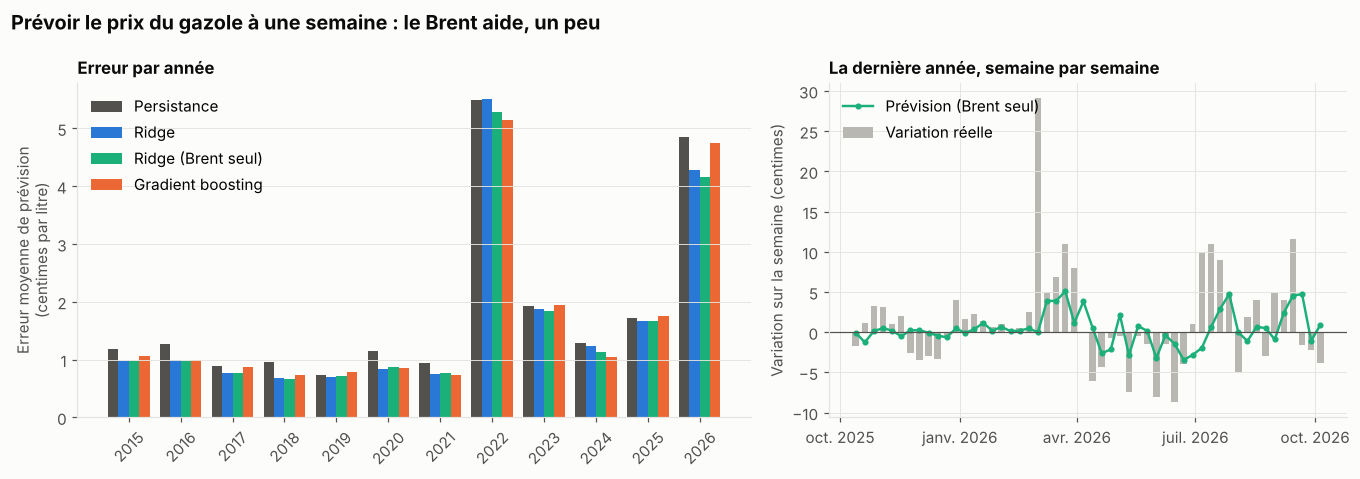

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
par_annee = erreurs.groupby("annee")[METHODES].mean()
largeur = 0.2
for k, (methode, couleur) in enumerate(zip(METHODES, [TEXTE_2, BLEU, AQUA, ORANGE])):
    ax.bar(par_annee.index + (k - 1.5) * largeur, par_annee[methode], width=largeur, color=couleur, label=methode[0].upper() + methode[1:])
ax.set_ylabel("Erreur moyenne de prévision\n(centimes par litre)")
ax.yaxis.set_major_formatter(virgule)
ax.set_xticks(par_annee.index, [str(a) for a in par_annee.index], rotation=45)
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
ax.set_title("Erreur par année", fontsize=11)

ax = axes[1]
MONTREE = "ridge (Brent seul)"
recent = previsions[pd.to_datetime(previsions["semaine"]) >= pd.Timestamp("2025-10-01")]
semaines = pd.to_datetime(recent["semaine"]) + pd.Timedelta(weeks=1)
ax.bar(semaines, recent["reel"] * 100, width=5, color="#b9b7b1", label="Variation réelle")
ax.plot(semaines, recent[MONTREE] * 100, color=AQUA, linewidth=1.6, marker="o", markersize=3, label="Prévision (Brent seul)")
ax.axhline(0, color=TEXTE_2, linewidth=0.8)
ax.set_ylabel("Variation sur la semaine (centimes)")
ax.yaxis.set_major_formatter(virgule)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{MOIS[mdates.num2date(x).month - 1]} {mdates.num2date(x).year}"))
ax.legend(frameon=False, loc="upper left")
ax.set_title("La dernière année, semaine par semaine", fontsize=11)
fig.suptitle("Prévoir le prix du gazole à une semaine : le Brent aide, un peu",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=TEXTE)
fig.tight_layout()
sauver(fig, "20_prevision")

Sur 613 semaines testées depuis 2015, la persistance se trompe en moyenne de 1,80 centimes. La régression sur toutes les variables fait 9 % mieux (1,63 centimes), mais ce gain est presque tout entier **avant 2022** : 20 % de 2015 à 2021, une différence nette (test de Diebold et Mariano : statistique de −5,1), contre 4 % depuis 2022, une différence que le hasard suffit à expliquer (p = 0,18). De 2023 à 2025, le gain n'est que de 3 % ; il remonte en 2026 (12 %).

**La régression sur le seul Brent fait mieux** : 11 % de gain en tout, et 7 % depuis 2022, une différence cette fois nette (p = 0,006). Avant 2022, ajouter le passé des prix et la marge ne changeait presque rien (20 % contre 19 % pour le Brent seul) ; depuis, ces variables brouillent la prévision.

Le **gradient boosting** n'apporte rien : sur toute la période, il ne fait ni mieux ni moins bien que la régression (p = 0,57), et avant 2022 il fait même moins bien (p = 0,02). Avec un historique de 367 semaines en 2015 à 978 aujourd'hui, et des relations presque linéaires, il n'a pas grand-chose de plus à apprendre.

Pour le **sens** de la variation, aucun modèle ne bat une règle naïve. Sur les 164 semaines où le prix varie d'au moins 2 centimes, la régression devine le sens 80 fois sur 100, mais répéter le sens de la semaine précédente le devine 84 fois sur 100 : les hausses et les baisses durent souvent plusieurs semaines.

Le retard de la pompe sur le pétrole, mis en évidence au notebook 03, rend donc la semaine suivante un peu prévisible, sans plus : l'essentiel des variations reste une surprise.

## Limites

- **Corrélation, pas causalité** : les valeurs de Shapley disent ce que le modèle utilise, pas ce qui ferait changer un prix. Une caractéristique comme le distributeur de billets est un indice du type de station, pas une cause.
- **Ce que le modèle ne voit pas** : volumes vendus, loyers, contrats d'approvisionnement, politique du gérant.
- **Enseignes d'aujourd'hui** : appliquées aux années passées, elles pénalisent surtout le modèle de 2019.
- **Ancienneté tronquée** : les données commencent en 2007, et 22 % des stations publient depuis le début ; leur ancienneté réelle est inconnue.
- **Une année moyenne** : le modèle décrit le niveau moyen d'une station sur les semaines où elle publie (au moins 26), pas ses variations semaine par semaine.
- **Prévision nationale** : la prévision à une semaine porte sur le prix médian, pas sur une station donnée. La remise propre de TotalEnergies à l'automne 2022 (20 puis 10 centimes sur ses stations) n'est pas retirée du prix, contrairement à celle de l'État.

## À retenir

- Un gradient boosting prédit l'écart de prix d'une station à **2,4 centimes près** en moyenne (R² de 0,75), 16 % mieux qu'une régression linéaire, et presque aussi bien dans un département qu'il n'a jamais vu. Une région entière jamais vue se prédit moins bien : l'Île-de-France a son propre niveau de prix.
- **L'enseigne pèse le plus** (2,7 centimes en moyenne), devant l'autoroute. TotalEnergies coûte 8 centimes de plus que les grandes surfaces, proche des 10 du notebook 04 ; les stations Total Access se placent au niveau de Carrefour.
- La concurrence locale pèse peu ; les variables de densité servent surtout à repérer le centre de l'agglomération parisienne, cher pour d'autres raisons.
- L'Île-de-France est la plus chère, surtout par le lieu ; la Bretagne la moins chère, par le lieu, ses enseignes et le peu d'autoroutes.
- En 2019 aussi, l'enseigne vient en tête, devant les services.
- **Prévoir la semaine suivante** : le Brent des semaines passées réduit l'erreur de 11 % par rapport à la persistance, de 7 % depuis 2022 ; pour le sens de la variation, une règle naïve fait mieux.
- Prochaine étape : le volet électrique, avec les bornes de recharge.

In [15]:
# Vérification : les chiffres cités dans le texte ci-dessus correspondent aux calculs de ce notebook.
# Ils sont aussi exportés pour le site.
CHIFFRES_JSON = Path('../rapports/chiffres_05.json')
CHIFFRES_JSON.write_text(json.dumps({k: round(float(v), 6) for k, v in sorted(chiffres.items())}, indent=1, ensure_ascii=False) + "\n")
CITES = {
 "mae_moyenne_hasard": [
  5.51364,
  0.05
 ],
 "mae_enseigne_hasard": [
  3.242897,
  0.05
 ],
 "r2_enseigne_hasard": [
  0.5728,
  5e-05
 ],
 "mae_lineaire_hasard": [
  2.836592,
  0.05
 ],
 "r2_lineaire_hasard": [
  0.664768,
  0.005
 ],
 "mae_gbm_hasard": [
  2.385232,
  0.05
 ],
 "r2_gbm_hasard": [
  0.751803,
  0.005
 ],
 "gain_lineaire": [
  15.912051,
  0.5
 ],
 "part_moins_2c": [
  59.333549,
  0.5
 ],
 "mae_gbm_dep": [
  2.562348,
  0.05
 ],
 "r2_gbm_dep": [
  0.722885,
  0.005
 ],
 "mae_gbm_reg": [
  3.013214,
  0.05
 ],
 "r2_gbm_reg": [
  0.643842,
  0.005
 ],
 "biais_region_Île-de-France": [
  4.876755,
  0.05
 ],
 "importance_Enseigne": [
  2.736041,
  0.05
 ],
 "ratio_enseigne": [
  2.421894,
  0.05
 ],
 "part_enseigne": [
  37.693575,
  0.5
 ],
 "perte_Enseigne": [
  0.579486,
  0.005
 ],
 "enseigne_E.Leclerc": [
  -4.229323,
  0.05
 ],
 "enseigne_TotalEnergies": [
  5.418919,
  0.05
 ],
 "enseigne_Eni": [
  7.38899,
  0.05
 ],
 "enseigne_Shell": [
  6.418283,
  0.05
 ],
 "dp_Eni_leclerc": [
  11.793926,
  0.05
 ],
 "dp_TotalEnergies_leclerc": [
  9.726713,
  0.05
 ],
 "enseigne_TotalEnergies Access": [
  -1.64502,
  0.05
 ],
 "enseigne_Carrefour": [
  -1.644326,
  0.05
 ],
 "dp_total_gms": [
  8.288347,
  0.5
 ],
 "nb04_total_gms": [
  9.768235,
  0.5
 ],
 "dp_access_gms": [
  1.494115,
  0.05
 ],
 "nb04_access_gms": [
  1.865465,
  0.05
 ],
 "autoroute": [
  12.050734,
  0.5
 ],
 "sans_e10_part": [
  18.947482,
  0.5
 ],
 "vend_e10_sans": [
  1.330112,
  0.05
 ],
 "vend_e10_avec": [
  -0.426504,
  0.05
 ],
 "sans_e10_voisins": [
  5.0,
  0.5
 ],
 "avec_e10_voisins": [
  10.0,
  0.5
 ],
 "sans_e10_inconnue": [
  28.742174,
  0.5
 ],
 "inconnue_part": [
  22.991481,
  0.5
 ],
 "atelier_avec": [
  1.642677,
  0.05
 ],
 "dab_avec": [
  -0.630362,
  0.05
 ],
 "dab_gms_part": [
  59.324915,
  0.5
 ],
 "gms_part": [
  42.33797,
  0.5
 ],
 "gms_proche": [
  -0.061145,
  0.005
 ],
 "gms_loin": [
  0.261199,
  0.005
 ],
 "perte_Concurrence": [
  0.008158,
  0.0005
 ],
 "coeur_seuil": [
  124.0,
  0.5
 ],
 "coeur_part_idf": [
  100.0,
  0.5
 ],
 "coeur_concurrence": [
  6.255007,
  0.05
 ],
 "hors_coeur_p10": [
  -0.796544,
  0.05
 ],
 "hors_coeur_p90": [
  0.61068,
  0.05
 ],
 "region_Île-de-France_écart à la moyenne": [
  5.092686,
  0.05
 ],
 "region_Île-de-France_lieu": [
  3.64312,
  0.05
 ],
 "region_Île-de-France_dont position": [
  1.872419,
  0.05
 ],
 "region_Île-de-France_dont concurrence": [
  1.7707,
  0.05
 ],
 "region_Île-de-France_enseigne": [
  1.075421,
  0.05
 ],
 "region_Bretagne_écart à la moyenne": [
  -3.452292,
  0.05
 ],
 "region_Bretagne_lieu": [
  -1.664579,
  0.05
 ],
 "region_Bretagne_enseigne": [
  -1.025146,
  0.05
 ],
 "region_Bretagne_grandes surfaces (%)": [
  55.97723,
  0.5
 ],
 "region_Bretagne_autoroute": [
  -0.630917,
  0.05
 ],
 "r2_gbm_2019": [
  0.728136,
  0.005
 ],
 "stations_2019": [
  9117.0,
  0.5
 ],
 "mae_gbm_2019": [
  2.047502,
  0.05
 ],
 "ecart_type_2019": [
  5.954537,
  0.05
 ],
 "ecart_type": [
  7.159309,
  0.05
 ],
 "importance_2019_Enseigne": [
  1.970624,
  0.05
 ],
 "ratio_enseigne_2019": [
  1.463605,
  0.05
 ],
 "importance_2019_Services": [
  1.346418,
  0.05
 ],
 "inconnue_part_2019": [
  33.870791,
  0.5
 ],
 "prev_semaines": [
  613.0,
  0.5
 ],
 "prev_total_persistance": [
  1.800163,
  0.005
 ],
 "prev_total_gain_ridge": [
  9.260996,
  0.5
 ],
 "prev_total_ridge": [
  1.63345,
  0.005
 ],
 "prev_avant_gain_ridge": [
  19.740872,
  0.5
 ],
 "dm_avant_ridge_persistance": [
  -5.069665,
  0.05
 ],
 "prev_depuis_gain_ridge": [
  3.940156,
  0.5
 ],
 "dm_depuis_ridge_persistance_p": [
  0.177531,
  0.005
 ],
 "prev_2023_2025_gain_ridge": [
  3.110666,
  0.5
 ],
 "prev_2026_gain_ridge": [
  11.763799,
  0.5
 ],
 "prev_total_gain_brent": [
  11.261601,
  0.5
 ],
 "prev_depuis_gain_brent": [
  7.133808,
  0.5
 ],
 "dm_depuis_brent_persistance_p": [
  0.006124,
  0.0005
 ],
 "prev_avant_gain_brent": [
  19.391664,
  0.5
 ],
 "dm_total_gbm_ridge_p": [
  0.572699,
  0.005
 ],
 "dm_avant_gbm_ridge_p": [
  0.020091,
  0.005
 ],
 "prev_historique_debut": [
  367.0,
  0.5
 ],
 "prev_historique_fin": [
  978.0,
  0.5
 ],
 "prev_grands": [
  164.0,
  0.5
 ],
 "prev_direction_ridge": [
  80.487805,
  0.5
 ],
 "prev_direction_naive": [
  84.146341,
  0.5
 ],
 "part_anciennete_tronquee": [
  21.751321,
  0.5
 ]
}
ecarts_cites = {cle: (valeur, chiffres.get(cle)) for cle, (valeur, tolerance) in CITES.items()
                if chiffres.get(cle) is None or not abs(chiffres[cle] - valeur) <= tolerance}
assert not ecarts_cites, f"Chiffres du texte à mettre à jour : {ecarts_cites}"
print(f"{len(CITES)} chiffres cités, tous conformes aux calculs")

91 chiffres cités, tous conformes aux calculs
